# Forecasting one SKU with General Forecast

You can [download this notebook](https://docs.generalforecast.com/notebooks/sku_forecasting_quickstart.ipynb) and run it in Jupyter.

This notebook forecasts weekly sales for one Walmart product with General Forecast's sklearn
interface: `fit` on the product's past weeks, then `predict` and `predict_quantiles` on weeks it
hasn't seen. Then we check the forecast against what actually sold, with the mean absolute error
and the mean absolute percentage error.

There's no training: `fit` keeps the rows, and the model reads them each time it predicts!

## Install

To install General Forecast, follow the steps in our [quickstart](https://docs.generalforecast.com/get-started/quickstart/).

The cell below installs it from PyPI, along with pandas and matplotlib.

In [1]:
%pip install -q generalforecast pandas matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import urllib.request
import zipfile

import matplotlib.pyplot as plt
import pandas as pd

import generalforecast as gf

## 1. Load one SKU's weekly sales

We use the M5 competition's Walmart data, from Nixtla's public copy (50 MB), and pick one of
store CA_1's best-selling products, `FOODS_3_586`. Its daily sales are added up into Walmart weeks, and each week
keeps the features known ahead of time: its price, how many days had an event, and how many had
SNAP (food stamp) payments.

In [3]:
if not os.path.exists("m5.zip"):
    urllib.request.urlretrieve(
        "https://github.com/Nixtla/m5-forecasts/raw/main/datasets/m5.zip", "m5.zip"
    )
with zipfile.ZipFile("m5.zip") as archive:
    sales = pd.read_csv(archive.open("sales_train_evaluation.csv"))
    calendar = pd.read_csv(archive.open("calendar.csv"), parse_dates=["date"])
    prices = pd.read_csv(archive.open("sell_prices.csv"))
calendar.insert(0, "d", [f"d_{day}" for day in range(1, len(calendar) + 1)])

store = sales[sales["store_id"] == "CA_1"].set_index("item_id").filter(like="d_")
sku = "FOODS_3_586"
daily = store.loc[sku].rename("units").rename_axis("d").reset_index()
daily = daily.merge(calendar, on="d")

weeks = daily.groupby("wm_yr_wk").agg(
    date=("date", "min"),
    days=("date", "size"),
    units=("units", "sum"),
    events=("event_name_1", "count"),
    snap_days=("snap_CA", "sum"),
)
weeks = weeks[weeks["days"] == 7].drop(columns="days").reset_index()
price = prices[(prices["store_id"] == "CA_1") & (prices["item_id"] == sku)]
weeks = weeks.merge(price[["wm_yr_wk", "sell_price"]], on="wm_yr_wk", how="left")
weeks = weeks.rename(columns={"sell_price": "price"}).drop(columns="wm_yr_wk")
print(sku, f"{len(weeks)} weeks")
weeks.tail()

FOODS_3_586 277 weeks


,date,units,events,snap_days,price
272,2016-04-16,275,0,0,1.68
273,2016-04-23,256,0,0,1.68
274,2016-04-30,300,3,6,1.68
275,2016-05-07,322,1,4,1.68
276,2016-05-14,280,0,0,1.68


## 2. Split into train and test weeks

The last 12 weeks are the test set. The 150 weeks before them are what the model is fit on.
`X` holds the features, including the date, which General Forecast reads as days since 1970,
weekday, day of month and month. `y` is the units sold.

In [4]:
FEATURES = ["date", "price", "events", "snap_days"]
TEST, HISTORY = 12, 150

train = weeks.iloc[-TEST - HISTORY : -TEST]
test = weeks.iloc[-TEST:]
X_train, y_train = train[FEATURES], train["units"]
X_test, y_test = test[FEATURES], test["units"]
print(f"{len(train)} train weeks, {len(test)} test weeks")

150 train weeks, 12 test weeks


## 3. Fit and predict

`fit` takes the training rows and their sales, like any sklearn regressor. The first run downloads
the model's weights from Hugging Face, which `allow_downloads=True` allows.

In [5]:
model = gf.Regressor("general-forecast/tabicl-v2-regressor", allow_downloads=True)
model.fit(X_train, y_train)

,model,'general-forecast/tabicl-v2-regressor'
,allow_downloads,True
,client,None
,strategy,None
,page_size,128
,backend,None
Name,Type,Value
context_,Table,"pyarrow.Table...,265,271,245]]"
feature_names_in_,"ndarray[object](4,)","['date','price','events','snap_days']"
n_features_in_,int,4
table_,RemoteTable,<RemoteTable ...v2-regressor'>


`predict` gives the median forecast per week:

In [6]:
model.predict(X_test.head())

array([239.57901, 271.7664 , 262.29947, 254.78293, 229.2579 ],
      dtype=float32)

`predict_quantiles` gives the quantiles you ask for. Here, the 10th, 50th and 90th
percentiles, so the 10th to 90th is an 80% range. Sales can't be negative, so we clip them at 0:

In [7]:
quantiles = model.predict_quantiles(X_test, quantiles=[0.1, 0.5, 0.9])
low, median, high = quantiles.clip(min=0).astype(float).T  # sales can't go below 0
results = test[["date", "units"]].assign(low=low, forecast=median, high=high)
results.round({"low": 1, "forecast": 1, "high": 1})

,date,units,low,forecast,high
265,2016-02-27,248,201.6,239.6,281.5
266,2016-03-05,264,230.6,271.8,313.9
267,2016-03-12,241,222.5,262.3,302.5
268,2016-03-19,256,214.5,254.8,296.5
269,2016-03-26,275,190.4,229.3,276.6
270,2016-04-02,289,214.8,259.3,306.9
271,2016-04-09,268,215.5,263.4,315.4
272,2016-04-16,275,214.7,259.1,306.0
273,2016-04-23,256,206.6,250.8,298.8
274,2016-04-30,300,211.6,262.8,318.7


## 4. Evaluating the forecast

- **MAE**, the mean absolute error: how many units a week the forecast is off by, on average.
- **MAPE**, the mean absolute percentage error: the same error as a share of the actual sales.
  Weeks with no sales are left out, as their percentage error is undefined.

In [8]:
actual = results["units"]
error = actual - results["forecast"]

mae = error.abs().mean()
sold = actual > 0
mape = (error[sold].abs() / actual[sold]).mean()
last_week = (actual - y_train.iloc[-1]).abs().mean()

print(f"MAE       {mae:.1f} units a week")
print(f"MAPE      {mape:.1%}")
print(f"          (repeating the last train week's sales instead: MAE {last_week:.1f})")

MAE       17.5 units a week
MAPE      6.2%
          (repeating the last train week's sales instead: MAE 28.5)


## 5. Plot the forecast

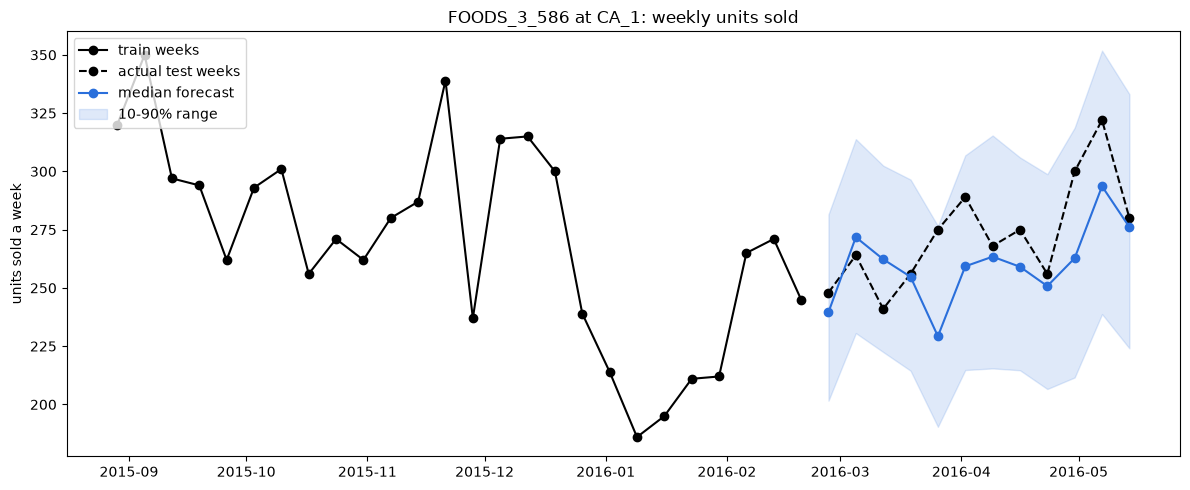

In [9]:
before = train.tail(26)
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(before["date"], before["units"], color="black", marker="o", label="train weeks")
ax.plot(
    results["date"],
    actual,
    color="black",
    marker="o",
    linestyle="--",
    label="actual test weeks",
)
ax.plot(
    results["date"],
    results["forecast"],
    color="#2a6fdb",
    marker="o",
    label="median forecast",
)
ax.fill_between(
    results["date"],
    results["low"],
    results["high"],
    color="#2a6fdb",
    alpha=0.15,
    label="10-90% range",
)
ax.set_title(f"{sku} at CA_1: weekly units sold")
ax.set_ylabel("units sold a week")
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()